# Régression : prix de vente des voitures (`Selling_Price`)

Dataset **car_dataset** — même démarche que le notebook *Taxi* : exploration, préparation, Linear Regression, Ridge, Decision Tree, Random Forest, puis export du meilleur modèle pour l'application.

In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib

In [2]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

## Description des variables

| Variable | Type | Description |
|---|---|---|
| `Kms_Driven` | Numérique | Kilométrage de la voiture |
| `Present_Price` | Numérique | Prix actuel d'une voiture neuve équivalente |
| `Fuel_Type` | Catégorielle | Carburant : `Petrol`, `Diesel`, `CNG` |
| `Seller_Type` | Catégorielle | Vendeur : `Dealer` (concessionnaire), `Individual` (particulier) |
| `Transmission` | Catégorielle | Boîte : `Manual`, `Automatic` |
| `Age` | Numérique | Âge de la voiture (années) |
| `Selling_Price` | Numérique | **Variable cible** : prix de vente |

In [3]:
# Importer les données
df = pd.read_csv('Car_dataset.csv')
df.head()

,Kms_Driven,Present_Price,Fuel_Type,Seller_Type,Transmission,Age,Selling_Price
0,27000,5.59,Petrol,Dealer,Manual,6,3.35
1,43000,9.54,Diesel,Dealer,Manual,7,4.75
2,6900,9.85,Petrol,Dealer,Manual,3,7.25
3,5200,4.15,Petrol,Dealer,Manual,9,2.85
4,42450,6.87,Diesel,Dealer,Manual,6,4.60


In [4]:
# Dimension des données
df.shape

(5861, 7)

In [5]:
# Afficher les infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5861 entries, 0 to 5860
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Kms_Driven     5861 non-null   int64  
 1   Present_Price  5861 non-null   float64
 2   Fuel_Type      5861 non-null   str    
 3   Seller_Type    5861 non-null   str    
 4   Transmission   5861 non-null   str    
 5   Age            5861 non-null   int64  
 6   Selling_Price  5861 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 437.8 KB


### <font color = 'bisque'>Exploration et préparation des données</font>

In [6]:
# sélection des variables quantitatives
quant_cols = df.select_dtypes(include='number')
quant_cols.head()

,Kms_Driven,Present_Price,Age,Selling_Price
0,27000,5.59,6,3.35
1,43000,9.54,7,4.75
2,6900,9.85,3,7.25
3,5200,4.15,9,2.85
4,42450,6.87,6,4.60


In [7]:
# vérification des valeurs manquantes
df.isnull().sum()

Kms_Driven       0
Present_Price    0
Fuel_Type        0
Seller_Type      0
Transmission     0
Age              0
Selling_Price    0
dtype: int64

In [8]:
# décrire les variables quantitatives
quant_cols.describe().T

,count,mean,std,min,25%,50%,75%,max
Kms_Driven,5861.0,75209.206108,39198.500980,500.00,53822.000000,71822.000000,87820.000000,538824.000000
Present_Price,5861.0,16.869948,9.659501,0.32,10.552438,15.375776,19.229938,102.661886
Age,5861.0,8.562532,3.099993,2.00,6.000000,8.000000,10.000000,22.000000
Selling_Price,5861.0,10.196217,5.874282,0.10,6.401756,9.049277,11.873727,41.903189


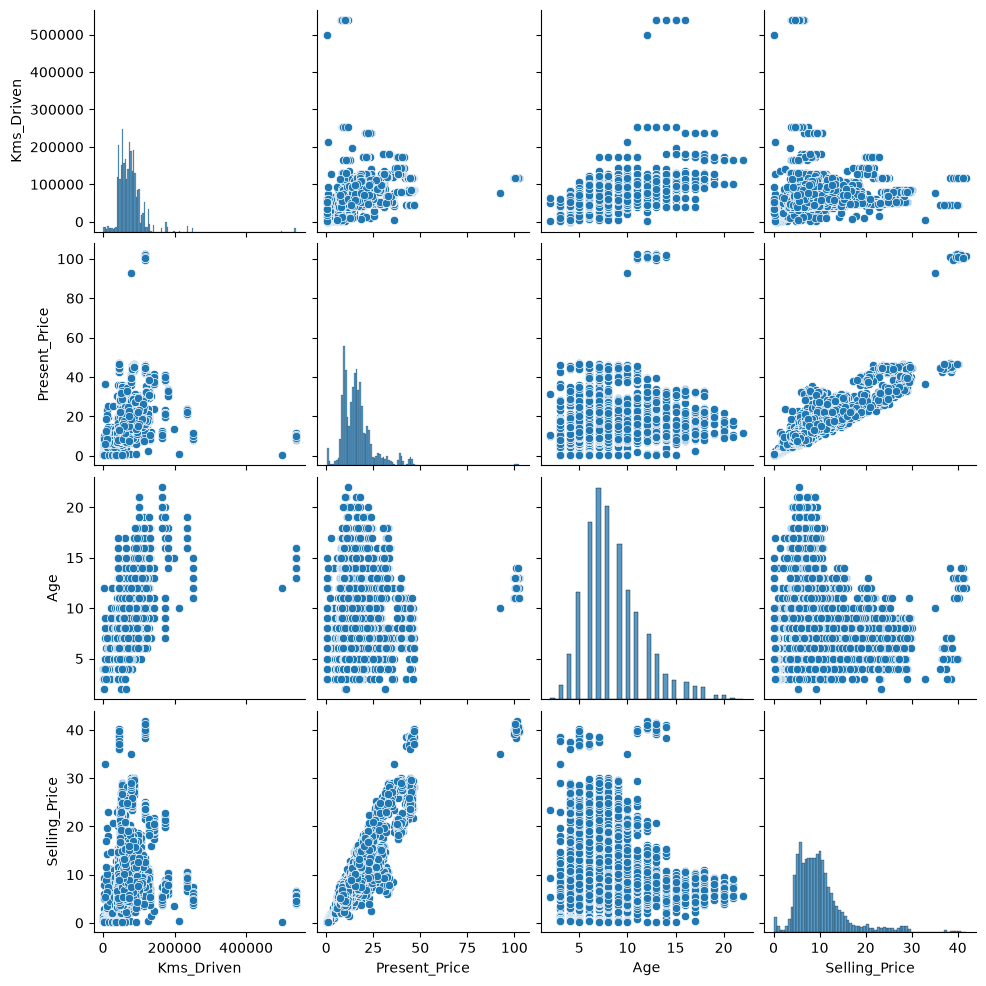

In [9]:
# pairplot des variables quantitatives
sns.pairplot(quant_cols)
plt.show()

In [10]:
# Fonction permettant de visualiser les boxplots
def boxplot_func(col):
    fig = px.box(df, x=col)
    fig.show()

In [11]:
# Appliquer la fonction boxplot_func
for col in quant_cols.columns:
    boxplot_func(col)

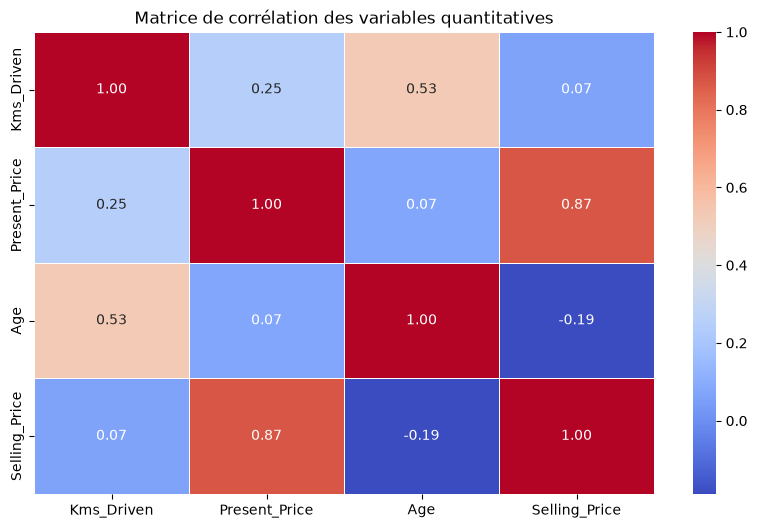

In [12]:
# Afficher la matrice de corrélation
plt.figure(figsize=(10, 6))
sns.heatmap(quant_cols.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matrice de corrélation des variables quantitatives")
plt.show()

In [13]:
# sélection des variables catégorielles
cat_cols = df.select_dtypes(exclude='number')
cat_cols.head()

,Fuel_Type,Seller_Type,Transmission
0,Petrol,Dealer,Manual
1,Diesel,Dealer,Manual
2,Petrol,Dealer,Manual
3,Petrol,Dealer,Manual
4,Diesel,Dealer,Manual


In [14]:
# describe des variables catégorielles
cat_cols.describe().T

,count,unique,top,freq
Fuel_Type,5861,3,Petrol,2743
Seller_Type,5861,2,Dealer,3765
Transmission,5861,2,Automatic,3007


In [15]:
# Fonction de visualisation du countplot
def countplot_func(cat_cols):
    for col in cat_cols:
        val = df[col].value_counts()
        fig = px.bar(x=val.index, y=val.values, color=val.index.astype(str), text_auto=True,
                     title=f"Répartition de : {col}")
        fig.show()

In [16]:
# Appliquer la fonction countplot_func
countplot_func(cat_cols)

In [17]:
# prix de vente moyen selon chaque variable catégorielle
for col in cat_cols.columns:
    fig = px.box(df, x=col, y='Selling_Price', color=col, title=f"Selling_Price selon {col}")
    fig.show()

In [18]:
# doublons
df.duplicated().sum()

np.int64(2)

In [19]:
# suppression des doublons
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(5859, 7)

In [20]:
# Imputer les valeurs manquantes des variables catégorielles avec le mode (par sécurité)
for col in cat_cols.columns:
    df.fillna({col: df[col].mode()[0]}, inplace=True)
df.isnull().sum()

Kms_Driven       0
Present_Price    0
Fuel_Type        0
Seller_Type      0
Transmission     0
Age              0
Selling_Price    0
dtype: int64

In [21]:
# Enregistrer les valeurs uniques des variables catégorielles (pour les listes déroulantes de l'app)
uniques = {col: sorted(df[col].unique().tolist()) for col in cat_cols.columns}
uniques

{'Fuel_Type': ['CNG', 'Diesel', 'Petrol'],
 'Seller_Type': ['Dealer', 'Individual'],
 'Transmission': ['Automatic', 'Manual']}

In [22]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
encoders = {}
for col in cat_cols.columns:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col])
    encoders[col] = encoder
df.head()

,Kms_Driven,Present_Price,Fuel_Type,Seller_Type,Transmission,Age,Selling_Price
0,27000,5.59,2,0,1,6,3.35
1,43000,9.54,1,0,1,7,4.75
2,6900,9.85,2,0,1,3,7.25
3,5200,4.15,2,0,1,9,2.85
4,42450,6.87,1,0,1,6,4.60


In [23]:
from sklearn.impute import KNNImputer
# Imputer les valeurs manquantes des variables quantitatives (par sécurité)
imputer = KNNImputer(n_neighbors=5)
df[:] = imputer.fit_transform(df)

On traite les valeurs aberrantes de `Kms_Driven` et `Age` uniquement.

- On ne modifie pas la cible `Selling_Price`, pour ne pas fausser les prix à prédire.
- On ne modifie pas `Present_Price` : ses valeurs élevées sont de vraies voitures haut de gamme, pas des erreurs. C'est la variable la plus corrélée au prix de vente (≈ 0,87) ; remplacer ces valeurs fait chuter le R² du Random Forest d'environ 0,95 à 0,74.

In [24]:
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # Détection des outliers (méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR
    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    features = df.columns.drop('Selling_Price')
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[features] = imputer.fit_transform(df[features])

In [25]:
# Application du traitement
for col in ['Kms_Driven', 'Age']:
    impute_func(df, col)

In [26]:
# réafficher les boxplots
for col in quant_cols.columns:
    boxplot_func(col)

In [27]:
# Fractionner les données
features = ['Kms_Driven', 'Present_Price', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Age']
x = df[features].values
y = df['Selling_Price'].values  # variable cible
x[:5], y[:5]

(array([[2.700e+04, 5.590e+00, 2.000e+00, 0.000e+00, 1.000e+00, 6.000e+00],
        [4.300e+04, 9.540e+00, 1.000e+00, 0.000e+00, 1.000e+00, 7.000e+00],
        [6.900e+03, 9.850e+00, 2.000e+00, 0.000e+00, 1.000e+00, 3.000e+00],
        [5.200e+03, 4.150e+00, 2.000e+00, 0.000e+00, 1.000e+00, 9.000e+00],
        [4.245e+04, 6.870e+00, 1.000e+00, 0.000e+00, 1.000e+00, 6.000e+00]]),
 array([3.35, 4.75, 7.25, 2.85, 4.6 ]))

In [28]:
# Normaliser x avec RobustScaler
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
scaler.fit(x)
x = scaler.transform(x)
x[:5]

array([[-1.3582024 , -1.12780522,  1.        ,  0.        ,  1.        ,
        -0.5       ],
       [-0.87334657, -0.67256991,  0.        ,  0.        ,  1.        ,
        -0.25      ],
       [-1.96730253, -0.63684258,  1.        ,  0.        ,  1.        ,
        -1.25      ],
       [-2.01881847, -1.29376443,  1.        ,  0.        ,  1.        ,
         0.25      ],
       [-0.89001349, -0.98028593,  0.        ,  0.        ,  1.        ,
        -0.5       ]])

In [29]:
from sklearn.model_selection import train_test_split
# Splitter les données en train (80%), val (10%) et test (10%)
x_train, x_vt, y_train, y_vt = train_test_split(x, y, test_size=0.2, random_state=42)
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size=0.5, random_state=42)
x_train.shape, x_val.shape, x_test.shape

((4687, 6), (586, 6), (586, 6))

### <font color = 'bisque'>Multiple Linear Regression</font>

In [30]:
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LinearRegression

# Validation croisée figée
cv = KFold(n_splits=5, shuffle=True, random_state=42)
params_lr = {'fit_intercept': [True, False], 'positive': [True, False]}
lr = LinearRegression()
grid_lr = GridSearchCV(lr, params_lr, cv=cv)
grid_lr.fit(x_train, y_train)
lr_model = grid_lr.best_estimator_
grid_lr.best_params_

{'fit_intercept': True, 'positive': False}

#### <font color = 'teal'>Évaluation de la Linear Regression</font>

In [31]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error

def evaluation(model):
    y_pred = model.predict(x_val)
    r2 = r2_score(y_val, y_pred)
    mse = mean_squared_error(y_val, y_pred)
    mae = mean_absolute_error(y_val, y_pred)
    rmse = root_mean_squared_error(y_val, y_pred)
    return r2, mse, mae, rmse

In [32]:
r2_lr, mse_lr, mae_lr, rmse_lr = evaluation(lr_model)
print(f'R2: {r2_lr:.3f}, MSE: {mse_lr:.3f}, MAE: {mae_lr:.3f}, RMSE: {rmse_lr:.3f}')

R2: 0.822, MSE: 6.778, MAE: 1.810, RMSE: 2.603


### <font color = 'bisque'>Ridge Regression</font>

In [33]:
from sklearn.linear_model import Ridge
params_rr = {'fit_intercept': [True, False], 'positive': [True, False], 'alpha': np.logspace(-8, 8, 100)}
rr = Ridge()
grid_rr = GridSearchCV(rr, params_rr, cv=cv)
grid_rr.fit(x_train, y_train)
rr_model = grid_rr.best_estimator_
grid_rr.best_params_

{'alpha': np.float64(23.644894126454073),
 'fit_intercept': True,
 'positive': False}

#### <font color = 'teal'>Évaluation du Ridge</font>

In [34]:
r2_rr, mse_rr, mae_rr, rmse_rr = evaluation(rr_model)
print(f'R2: {r2_rr:.3f}, MSE: {mse_rr:.3f}, MAE: {mae_rr:.3f}, RMSE: {rmse_rr:.3f}')

R2: 0.822, MSE: 6.783, MAE: 1.810, RMSE: 2.604


### <font color = 'bisque'>Decision Tree Regressor</font>

In [35]:
from sklearn.tree import DecisionTreeRegressor
params_dt = {'max_depth': np.arange(1, 30), 'criterion': ['squared_error', 'absolute_error']}
dt = DecisionTreeRegressor(random_state=42)
grid_dt = GridSearchCV(dt, params_dt, cv=cv, n_jobs=-1)
grid_dt.fit(x_train, y_train)
dt_model = grid_dt.best_estimator_
grid_dt.best_params_

{'criterion': 'squared_error', 'max_depth': np.int64(8)}

#### <font color = 'teal'>Évaluation du Decision Tree Regressor</font>

In [36]:
r2_dt, mse_dt, mae_dt, rmse_dt = evaluation(dt_model)
print(f'R2: {r2_dt:.3f}, MSE: {mse_dt:.3f}, MAE: {mae_dt:.3f}, RMSE: {rmse_dt:.3f}')

R2: 0.928, MSE: 2.728, MAE: 1.211, RMSE: 1.652


### <font color = 'bisque'>Random Forest Regressor</font>

In [37]:
from sklearn.ensemble import RandomForestRegressor
params_rf = {'n_estimators': np.arange(10, 100, 10), 'max_depth': np.arange(1, 15)}
rf = RandomForestRegressor(random_state=42)
grid_rf = GridSearchCV(rf, params_rf, cv=cv, n_jobs=-1)
grid_rf.fit(x_train, y_train)
rf_model = grid_rf.best_estimator_
grid_rf.best_params_

{'max_depth': np.int64(14), 'n_estimators': np.int64(90)}

#### <font color = 'teal'>Évaluation du Random Forest</font>

In [38]:
r2_rf, mse_rf, mae_rf, rmse_rf = evaluation(rf_model)
print(f'R2: {r2_rf:.3f}, MSE: {mse_rf:.3f}, MAE: {mae_rf:.3f}, RMSE: {rmse_rf:.3f}')

R2: 0.947, MSE: 2.009, MAE: 1.053, RMSE: 1.417


### <font color = 'bisque'>Comparaison des modèles</font>

In [39]:
resultats = pd.DataFrame({
    'Modèle': ['Linear Regression', 'Ridge', 'Decision Tree', 'Random Forest'],
    'R2': [r2_lr, r2_rr, r2_dt, r2_rf],
    'MSE': [mse_lr, mse_rr, mse_dt, mse_rf],
    'MAE': [mae_lr, mae_rr, mae_dt, mae_rf],
    'RMSE': [rmse_lr, rmse_rr, rmse_dt, rmse_rf],
})
for metrique in ['R2', 'MSE', 'MAE', 'RMSE']:
    fig = px.bar(resultats, x=metrique, y='Modèle', color='Modèle', text_auto='.3f', title=f"Comparaison : {metrique}")
    fig.show()
resultats

,Modèle,R2,MSE,MAE,RMSE
0,Linear Regression,0.821750,6.778103,1.810026,2.603479
1,Ridge,0.821610,6.783412,1.810441,2.604498
2,Decision Tree,0.928271,2.727542,1.210536,1.651527
3,Random Forest,0.947176,2.008673,1.053140,1.417277


### <font color = 'bisque'>Tester le modèle le plus performant</font>

In [40]:
# choix automatique du meilleur modèle selon le R2
modeles = {'Linear Regression': lr_model, 'Ridge': rr_model, 'Decision Tree': dt_model, 'Random Forest': rf_model}
best_name = resultats.sort_values('R2', ascending=False).iloc[0]['Modèle']
best_model = modeles[best_name]
print('Meilleur modèle :', best_name)

y_pred_test = best_model.predict(x_test)
print(f"R2 test : {r2_score(y_test, y_pred_test):.3f}")
print(f"MAE test : {mean_absolute_error(y_test, y_pred_test):.3f}")

Meilleur modèle : Random Forest
R2 test : 0.952
MAE test : 1.002


In [41]:
# échantillon de 10 prédictions sur les données test
for i in range(10):
    print(f"Prédiction {i + 1} : {y_pred_test[i]:.2f} -- Réel : {y_test[i]:.2f}")

Prédiction 1 : 15.10 -- Réel : 17.01
Prédiction 2 : 9.51 -- Réel : 9.00
Prédiction 3 : 11.70 -- Réel : 10.36
Prédiction 4 : 9.76 -- Réel : 8.34
Prédiction 5 : 6.66 -- Réel : 6.98
Prédiction 6 : 8.66 -- Réel : 8.51
Prédiction 7 : 8.04 -- Réel : 7.52
Prédiction 8 : 5.41 -- Réel : 5.27
Prédiction 9 : 23.92 -- Réel : 25.19
Prédiction 10 : 10.08 -- Réel : 14.73


### <font color = 'bisque'>Export du modèle pour l'application</font>

On sauvegarde le modèle, le scaler, les encodeurs, les valeurs uniques et la liste des variables dans un seul fichier.

In [42]:
joblib.dump({
    'model': best_model,
    'scaler': scaler,
    'encoders': encoders,
    'uniques': uniques,
    'features': features,
}, 'car_dataset_model.pkl')
print('Modèle sauvegardé : car_dataset_model.pkl')

Modèle sauvegardé : car_dataset_model.pkl
